In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

from torch.utils.data import DataLoader, Subset

import numpy as np
import random
import time
import pandas as pd
import matplotlib.pyplot as plt
import copy


device = "cuda" if torch.cuda.is_available() else "cpu"

print("device:", device)


SEED = 42

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device: cuda


In [2]:
weights = models.ResNet18_Weights.IMAGENET1K_V1


train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        weights.transforms().mean,
        weights.transforms().std
    )
])


eval_transform = weights.transforms()



dataset = datasets.OxfordIIITPet(
    root="data",
    split="trainval",
    target_types="category",
    download=True,
    transform=train_transform
)


targets = np.array(dataset._labels)


# ambil 10 kelas
idx_10 = np.where(targets < 10)[0]


indices_train, indices_temp = train_test_split(
    idx_10,
    test_size=0.30,
    random_state=42,
    stratify=targets[idx_10]
)


indices_val, indices_test = train_test_split(
    indices_temp,
    test_size=0.50,
    random_state=42,
    stratify=targets[indices_temp]
)


train_set = Subset(dataset, indices_train)
val_set = Subset(dataset, indices_val)
test_set = Subset(dataset, indices_test)


print(
    len(train_set),
    len(val_set),
    len(test_set)
)

100%|██████████| 792M/792M [00:45<00:00, 17.2MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.43MB/s]


697 149 150


In [4]:
batch_size=32


train_loader = DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True
)


val_loader = DataLoader(
    val_set,
    batch_size=batch_size
)


test_loader = DataLoader(
    test_set,
    batch_size=batch_size
)

In [5]:
def create_model(mode):

    if mode=="scratch":

        model=models.resnet18(
            weights=None
        )

    else:

        model=models.resnet18(
            weights=weights
        )


    model.fc=nn.Linear(
        512,
        10
    )


    if mode=="feature":

        for p in model.parameters():
            p.requires_grad=False

        for p in model.fc.parameters():
            p.requires_grad=True



    elif mode=="finetune":

        for p in model.parameters():
            p.requires_grad=False

        for p in model.layer4.parameters():
            p.requires_grad=True

        for p in model.fc.parameters():
            p.requires_grad=True


    return model.to(device)

In [6]:
def train_model(model, optimizer, epochs=5):

    criterion=nn.CrossEntropyLoss()

    best_loss=999
    best_model=None

    history=[]

    start=time.time()


    for epoch in range(epochs):

        model.train()

        train_loss=0


        for x,y in train_loader:

            x=x.to(device)
            y=y.to(device)


            optimizer.zero_grad()

            out=model(x)

            loss=criterion(out,y)

            loss.backward()

            optimizer.step()

            train_loss += loss.item()



        model.eval()

        val_loss=0
        preds=[]
        labels=[]


        with torch.no_grad():

            for x,y in val_loader:

                x=x.to(device)
                y=y.to(device)

                out=model(x)

                loss=criterion(out,y)

                val_loss += loss.item()


                preds.extend(
                    out.argmax(1).cpu().numpy()
                )

                labels.extend(
                    y.cpu().numpy()
                )


        val_acc=accuracy_score(
            labels,
            preds
        )


        avg_val_loss=val_loss/len(val_loader)


        history.append([
            epoch+1,
            train_loss/len(train_loader),
            avg_val_loss,
            val_acc
        ])


        print(
            "Epoch",
            epoch+1,
            "val acc",
            val_acc
        )


        if avg_val_loss < best_loss:

            best_loss=avg_val_loss
            best_model=copy.deepcopy(model)


    duration=time.time()-start


    return best_model, pd.DataFrame(
        history,
        columns=[
            "epoch",
            "train_loss",
            "val_loss",
            "val_acc"
        ]
    ), duration

In [7]:
def evaluate_test(model):

    model.eval()

    preds=[]
    labels=[]

    with torch.no_grad():

        for x,y in test_loader:

            x=x.to(device)

            out=model(x)

            preds.extend(
                out.argmax(1).cpu().numpy()
            )

            labels.extend(
                y.numpy()
            )


    acc=accuracy_score(
        labels,
        preds
    )

    f1=f1_score(
        labels,
        preds,
        average="macro"
    )

    return acc,f1

In [8]:
results=[]


model_b1=create_model(
    "scratch"
)


trainable_b1=sum(
    p.numel()
    for p in model_b1.parameters()
    if p.requires_grad
)


optimizer_b1=optim.AdamW(
    model_b1.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)


model_b1,hist_b1,time_b1=train_model(
    model_b1,
    optimizer_b1,
    epochs=5
)


acc_b1,f1_b1=evaluate_test(
    model_b1
)


results.append([
    "B1 Scratch",
    trainable_b1,
    "1e-3",
    time_b1,
    acc_b1,
    f1_b1
])


print("B1 selesai")

Epoch 1 val acc 0.1342281879194631
Epoch 2 val acc 0.2080536912751678
Epoch 3 val acc 0.16778523489932887
Epoch 4 val acc 0.09395973154362416
Epoch 5 val acc 0.174496644295302
B1 selesai


In [9]:
model_b2=create_model(
    "feature"
)


trainable_b2=sum(
    p.numel()
    for p in model_b2.parameters()
    if p.requires_grad
)


optimizer_b2=optim.AdamW(
    filter(
        lambda p:p.requires_grad,
        model_b2.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-2
)


model_b2,hist_b2,time_b2=train_model(
    model_b2,
    optimizer_b2,
    epochs=5
)


acc_b2,f1_b2=evaluate_test(
    model_b2
)


results.append([
    "B2 Feature Extraction",
    trainable_b2,
    "1e-3",
    time_b2,
    acc_b2,
    f1_b2
])


print("B2 selesai")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 160MB/s]


Epoch 1 val acc 0.436241610738255
Epoch 2 val acc 0.7046979865771812
Epoch 3 val acc 0.7449664429530202
Epoch 4 val acc 0.7516778523489933
Epoch 5 val acc 0.7986577181208053
B2 selesai


In [10]:
model_b3=create_model(
    "finetune"
)


trainable_b3=sum(
    p.numel()
    for p in model_b3.parameters()
    if p.requires_grad
)


optimizer_b3=optim.AdamW(
[
    {
        "params":model_b3.layer4.parameters(),
        "lr":1e-4
    },
    {
        "params":model_b3.fc.parameters(),
        "lr":1e-3
    }
],
weight_decay=1e-2
)


model_b3,hist_b3,time_b3=train_model(
    model_b3,
    optimizer_b3,
    epochs=5
)


acc_b3,f1_b3=evaluate_test(
    model_b3
)


results.append([
    "B3 Fine Tuning",
    trainable_b3,
    "layer4:1e-4 fc:1e-3",
    time_b3,
    acc_b3,
    f1_b3
])


print("B3 selesai")

Epoch 1 val acc 0.6912751677852349
Epoch 2 val acc 0.7986577181208053
Epoch 3 val acc 0.825503355704698
Epoch 4 val acc 0.8523489932885906
Epoch 5 val acc 0.8590604026845637
B3 selesai


In [11]:
pd.DataFrame(
    results,
    columns=[
        "Experiment",
        "Trainable Params",
        "Learning Rate",
        "Time",
        "Test Accuracy",
        "Macro F1"
    ]
)

,Experiment,Trainable Params,Learning Rate,Time,Test Accuracy,Macro F1
0,B1 Scratch,11181642,1e-3,59.508870,0.200000,0.157890
1,B2 Feature Extraction,5130,1e-3,43.442150,0.813333,0.812476
2,B3 Fine Tuning,8398858,layer4:1e-4 fc:1e-3,43.755166,0.793333,0.792825


In [12]:
no_aug_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        weights.transforms().mean,
        weights.transforms().std
    )
])


dataset_no_aug = datasets.OxfordIIITPet(
    root="data",
    split="trainval",
    target_types="category",
    download=True,
    transform=no_aug_transform
)


train_no_aug = Subset(
    dataset_no_aug,
    indices_train
)


train_loader_no_aug = DataLoader(
    train_no_aug,
    batch_size=32,
    shuffle=True
)

In [13]:
old_loader = train_loader

train_loader = train_loader_no_aug

In [14]:
model_b4=create_model(
    "feature"
)


optimizer_b4=optim.AdamW(
    filter(
        lambda p:p.requires_grad,
        model_b4.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-2
)


model_b4,hist_b4,time_b4=train_model(
    model_b4,
    optimizer_b4,
    epochs=5
)


acc_b4,f1_b4=evaluate_test(
    model_b4
)


results.append([
    "B4 Without Augmentation",
    5130,
    "1e-3",
    time_b4,
    acc_b4,
    f1_b4
])


print(acc_b4,f1_b4)

Epoch 1 val acc 0.5100671140939598
Epoch 2 val acc 0.7516778523489933
Epoch 3 val acc 0.6510067114093959
Epoch 4 val acc 0.7516778523489933
Epoch 5 val acc 0.7651006711409396
0.7666666666666667 0.7688079023724186


In [15]:
train_loader = old_loader

In [16]:
final_results=pd.DataFrame(
    results,
    columns=[
        "Experiment",
        "Trainable Params",
        "Learning Rate",
        "Time",
        "Test Accuracy",
        "Macro F1"
    ]
)


final_results.to_csv(
    "metrics.csv",
    index=False
)


final_results

,Experiment,Trainable Params,Learning Rate,Time,Test Accuracy,Macro F1
0,B1 Scratch,11181642,1e-3,59.508870,0.200000,0.157890
1,B2 Feature Extraction,5130,1e-3,43.442150,0.813333,0.812476
2,B3 Fine Tuning,8398858,layer4:1e-4 fc:1e-3,43.755166,0.793333,0.792825
3,B4 Without Augmentation,5130,1e-3,37.845683,0.766667,0.768808


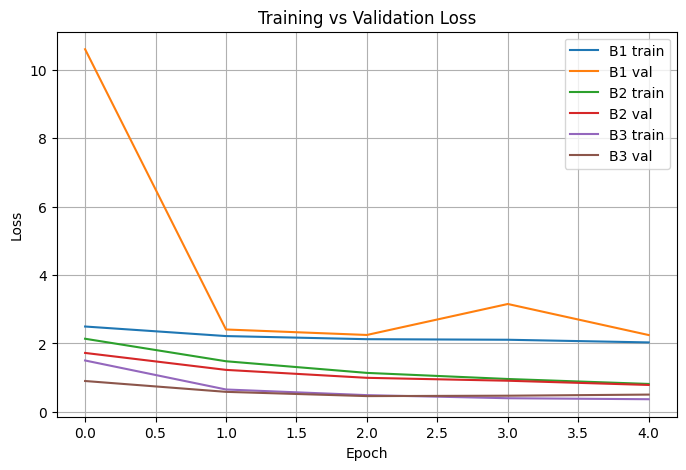

In [17]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8,5))

plt.plot(
    hist_b1["train_loss"],
    label="B1 train"
)

plt.plot(
    hist_b1["val_loss"],
    label="B1 val"
)


plt.plot(
    hist_b2["train_loss"],
    label="B2 train"
)

plt.plot(
    hist_b2["val_loss"],
    label="B2 val"
)


plt.plot(
    hist_b3["train_loss"],
    label="B3 train"
)

plt.plot(
    hist_b3["val_loss"],
    label="B3 val"
)


plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()

plt.savefig(
    "loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
import torch.nn.functional as F


model_best=model_b2

model_best.eval()


wrong=[]


with torch.no_grad():

    for idx,(x,y) in enumerate(test_loader):

        x=x.to(device)

        out=model_best(x)

        prob=F.softmax(out,dim=1)

        pred=out.argmax(1).cpu()

        conf=prob.max(1).values.cpu()


        for i in range(len(y)):

            if pred[i] != y[i]:

                wrong.append(
                    (
                    x[i].cpu(),
                    y[i].item(),
                    pred[i].item(),
                    conf[i].item()
                    )
                )


len(wrong)

36

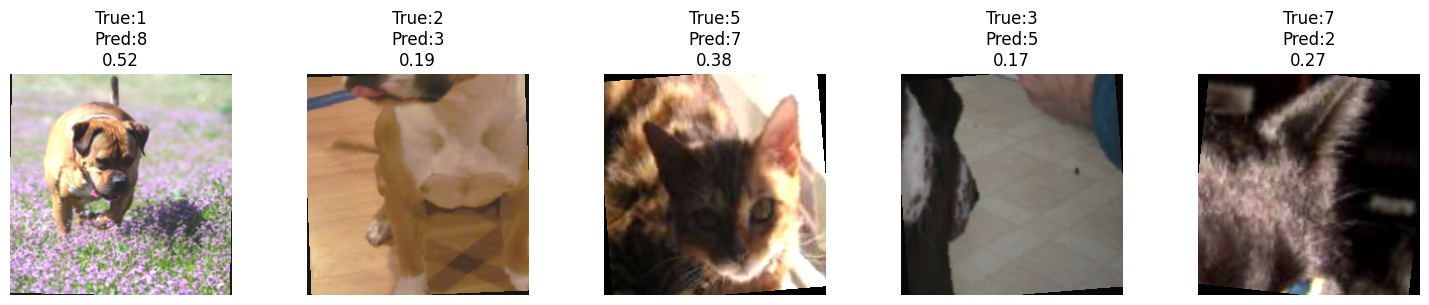

In [20]:
fig,axs=plt.subplots(
    1,
    5,
    figsize=(15,3)
)


for i in range(5):

    img,label,pred,conf=wrong[i]


    img=img.permute(1,2,0)


    mean=torch.tensor(
        weights.transforms().mean
    )

    std=torch.tensor(
        weights.transforms().std
    )


    img=img*std+mean

    img=torch.clamp(img,0,1)


    axs[i].imshow(img)

    axs[i].set_title(
        f"True:{label}\nPred:{pred}\n{conf:.2f}"
    )

    axs[i].axis("off")


plt.tight_layout()

plt.savefig(
    "failure_analysis.png",
    dpi=300
)

plt.show()

In [21]:
# cek mapping label ke nama kelas Oxford-IIIT Pet

full_dataset = datasets.OxfordIIITPet(
    root="data",
    split="trainval",
    target_types="category",
    download=True
)

print(full_dataset.classes[:10])

['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair']


In [22]:
print(wrong[:5])

[(tensor([[[-1.6727, -1.6727,  1.4098,  ..., -1.6727, -1.6727, -1.6727],
         [-1.6727, -1.6727,  1.4612,  ..., -1.6727, -1.6727, -1.6727],
         [-1.6727, -1.6727,  1.5297,  ...,  0.7591,  0.7248,  0.7077],
         ...,
         [ 0.6563,  0.6734,  0.6563,  ...,  0.5878, -1.6727, -1.6727],
         [-1.6727, -1.6727, -1.6727,  ..., -0.2856, -1.6727, -1.6727],
         [-1.6727, -1.6727, -1.6727,  ...,  0.4166, -1.6727, -1.6727]],

        [[-1.5805, -1.5805,  1.7458,  ..., -1.5805, -1.5805, -1.5805],
         [-1.5805, -1.5805,  1.7808,  ..., -1.5805, -1.5805, -1.5805],
         [-1.5805, -1.5805,  1.8333,  ...,  1.3081,  1.2556,  1.2556],
         ...,
         [ 0.9055,  0.7829,  0.5903,  ...,  0.9930, -1.5805, -1.5805],
         [-1.5805, -1.5805, -1.5805,  ...,  0.4153, -1.5805, -1.5805],
         [-1.5805, -1.5805, -1.5805,  ...,  0.4153, -1.5805, -1.5805]],

        [[-1.3513, -1.3513,  1.4025,  ..., -1.3513, -1.3513, -1.3513],
         [-1.3513, -1.3513,  1.4374,  ..., 